# First training

Policy gradient on the Zamboni task (`pg1`, Algorithm 1): GPOMDP with its baseline and Adam, with first-guess values n = 100 episodes per iteration, K = 1000 iterations and lr = 0.001.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from zamboni.controllers import PDController
from zamboni.env import RINK_HALF_X, RINK_HALF_Y, TARGET_WINDOW, ZamboniEnv
from zamboni.policy import LinearGaussianPolicy
from zamboni.training import Config, evaluate, train

cfg = Config()
policy, history = train(cfg)
result = evaluate(policy.act, cfg.mass, cfg.energy_coeff)
print(f"test return {result['return']:.0f}, targets reached {result['targets_reached']:.2f} of 3")

test return -179114, targets reached 0.23 of 3


## Learning curves

The return is the batch average at each iteration, an estimate of J(θ_k) for the policy with its noise. σ is the noise of the policy, learned with the other parameters.

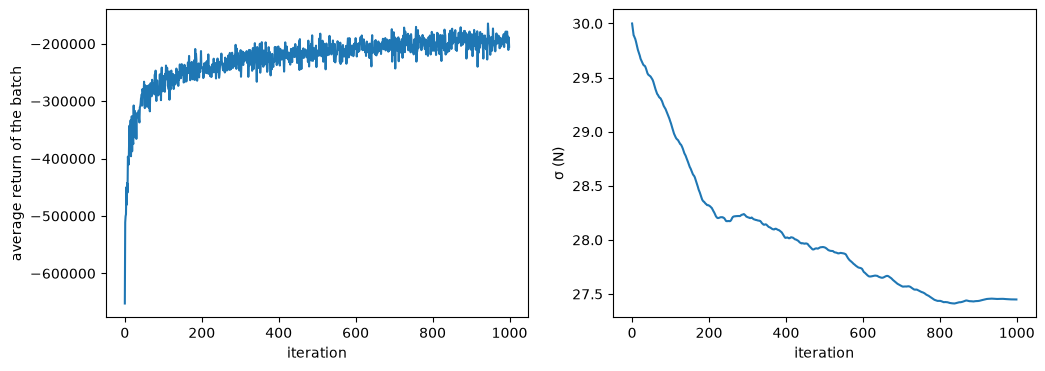

In [2]:
fig, (ax_return, ax_sigma) = plt.subplots(1, 2, figsize=(12, 4))
ax_return.plot(history["return"])
ax_return.set_xlabel("iteration")
ax_return.set_ylabel("average return of the batch")
ax_sigma.plot(history["sigma"])
ax_sigma.set_xlabel("iteration")
ax_sigma.set_ylabel("σ (N)")
plt.show()

## Against hand-designed controllers

Two PD controllers drive the robot on the same test episodes as the learned policy: the critically damped PD with kp = 10 N/m, and the PD with the gains of the LQR. The dashed lines are the two PDs without noise, while the curve is the learned policy with its noise, which costs extra: the fair comparison is the table above the plot.

PG                   return   -179114, targets reached 0.23 of 3
critically damped PD return    -87155, targets reached 3.00 of 3
LQR PD               return    -81592, targets reached 3.00 of 3


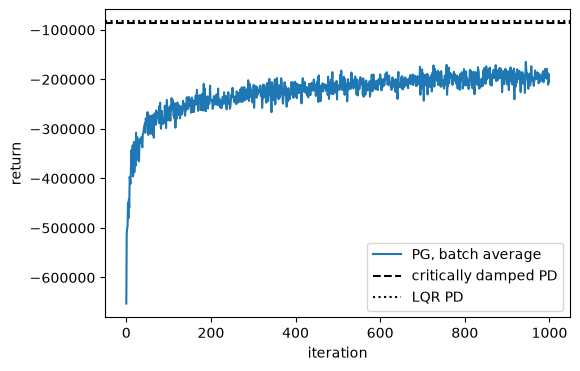

In [3]:
controllers = {
    "critically damped PD": PDController.critically_damped(cfg.mass),
    "LQR PD": PDController.lqr(cfg.mass, cfg.energy_coeff),
}
results = {"PG": result} | {
    name: evaluate(controller.act, cfg.mass, cfg.energy_coeff)
    for name, controller in controllers.items()
}
for name, r in results.items():
    print(f"{name:20} return {r['return']:9.0f}, targets reached {r['targets_reached']:.2f} of 3")

plt.figure(figsize=(6, 4))
plt.plot(history["return"], label="PG, batch average")
for name, style in [("critically damped PD", "--"), ("LQR PD", ":")]:
    plt.axhline(results[name]["return"], color="black", linestyle=style, label=name)
plt.xlabel("iteration")
plt.ylabel("return")
plt.legend()
plt.show()

## The policy along the training

The path of the robot in the first 20 s window (one target), driven by the mean command without noise, at three points of the training. At iteration 0 the weights are zero, so the mean command is zero and the robot does not move.

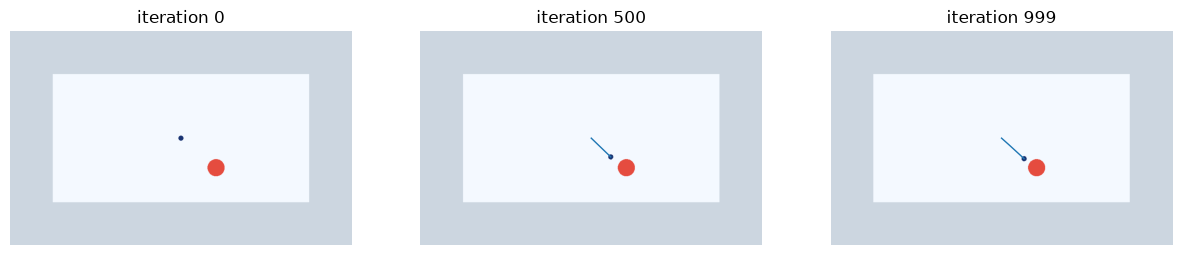

In [4]:
def first_window(theta, seed=0):
    replay = LinearGaussianPolicy()
    replay.theta = theta
    env = ZamboniEnv(render_mode="rgb_array")
    obs, _ = env.reset(seed=seed)
    path = [obs[:2]]
    for _ in range(TARGET_WINDOW - 1):  # stop before the target changes
        obs, *_ = env.step(replay.act(obs))
        path.append(obs[:2])
    return env.render(), np.array(path)


view = [-RINK_HALF_X - 10, RINK_HALF_X + 10, -RINK_HALF_Y - 10, RINK_HALF_Y + 10]  # as render()
iterations = [0, cfg.iterations // 2, cfg.iterations - 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, k in zip(axes, iterations, strict=True):
    image, path = first_window(history["theta"][k])
    ax.imshow(image, extent=view)
    ax.plot(path[:, 0], path[:, 1], color="tab:blue", linewidth=1)
    ax.set_title(f"iteration {k}")
    ax.axis("off")
plt.show()